# Cell cycle phase distribution — T47D, 3 dpt Palbociclib

Reads a FlowJo cell-cycle CSV export (`Sample name`, SubG0/G1/S/G2 "Freq. of Parent"
columns), parses CellLine/Treatment/Replicate directly out of the sample name (e.g.
`CDK2_S261G_Palbo_2` -> CellLine=`CDK2_S261G`, Treatment=`Palbo`, Replicate=`2`),
averages replicates, and produces two pairs of figures, each split into the ABE-derived
lines (`ABE_NT`, `CDK2_S261G`, `CDK4_I51V`) and the CBE-derived lines (`CBE_NT`,
`CDK6_G53S`, `CDK6_R46W`, `CDK6_R168H`):

1. **Figure 1a/1b** — stacked bar of Sub-G0 / G0-G1 / S / G2-M percent composition per condition.
1c. **Figure 1c/1d** — the same stacked bars for DMSO and Palbo only, grouped by treatment
   (cell lines as the bars within each treatment), matching the Figure 2 layout.
2. **Figure 2a/2b** — dot + bar plot of **%S phase only** (DMSO and Palbo only; the
   serum-free condition is excluded from these plots), with SD error bars, individual
   replicate points, and significance asterisks comparing each variant's Palbo condition
   against its NT control's Palbo condition (Welch's two-sided t-test, Bonferroni-corrected).

Cell-line x-axis labels have underscores replaced with spaces and gene names (`CDK2`,
`CDK4`, `CDK6`) italicized automatically.

Edit the **Configuration** cell to point at a different data CSV, change which cell lines
go in each group, or change the statistical comparison, then re-run all cells.

## Imports

In [1]:
import re

import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

import figure_style
figure_style.apply_style()

# Helvetica for this notebook's figures. Nimbus Sans / TeX Gyre Heros are metric-identical
# Helvetica clones, used only if Helvetica itself isn't installed on the machine running this.
plt.rcParams["font.family"] = ["Helvetica", "Nimbus Sans", "TeX Gyre Heros", "DejaVu Sans"]
# Keep SVG text as real, editable text (font-family Helvetica) instead of outlined glyphs.
plt.rcParams["svg.fonttype"] = "none"

## Configuration

In [2]:
# Phase fills for the stacked bar plots (Figure 1) only. Swap back to
# figure_style.PHASE_COLORS for the original muted palette.
PHASE_COLORS = {
    "G0": "#DE918F",   # Sub-G1
    "G1": "#B2CEE7",
    "S": "#668FCA",
    "G2M": "#C0A4C7",
}
PHASE_ORDER = ["G0", "G1", "S", "G2M"]
PHASE_LABELS = {"G0": "Sub-G1", "G1": "G1", "S": "S", "G2M": "G2/M"}  # legend display text

DATA_CSV = "20260908_T47D_cell_cycle.csv"        # FlowJo table export, all conditions
OUT_PREFIX = "T47D_cell_cycle_stacked"            # output file prefix (.svg/.png)
TITLE = "T47D"

# Cell lines are split into these two groups for every plot below.
ABE_LINES = ["ABE_NT", "CDK2_S261G", "CDK4_I51V"]
CBE_LINES = ["CBE_NT", "CDK6_G53S", "CDK6_R46W"]
CELL_LINE_LABELS = {
    "CDK6_G53S": "CDK6 G53S_M54I",   # <- new label here
    "CDK6_R46W": "CDK6 R44C_R46W",   # <- new label here
}

TREATMENT_ORDER = ["DMSO", "Palbo", "ss"]         # left-to-right bar order within a group
TREATMENT_LABELS = {"Palbo": "Palbociclib", "ss": "serum free"}           # display label overrides for x-axis text

# Dot colors for the %S-phase plot, keyed by treatment
TREATMENT_COLORS = figure_style.TREATMENT_COLORS
COMPARISON_TREATMENT = "Palbo"                    # treatment compared to the NT control (stats tables below)
SPHASE_SIG_TREATMENTS = ["DMSO", "Palbo"]         # treatments that get variant-vs-NT brackets on the %S-phase plots
# Bonferroni family for the variant-vs-NT Welch tests:
#   "figure"    -> every comparison drawn on one %S-phase plot (variants x SPHASE_SIG_TREATMENTS;
#                  e.g. 2 variants x DMSO/Palbo = 4 tests, so p_adj = p x 4)
#   "treatment" -> only the comparisons within the same treatment (e.g. 2 tests per treatment)
BONFERRONI_FAMILY = "figure"

# The %S-phase plots are grouped by treatment (DMSO / Palbo), with cell
# lines as the bars within each group, so each cell line gets its own dot color here.
CELL_LINE_COLORS = {
    "ABE_NT": "#8C8C86", "CBE_NT": "#8C8C86",
    "CDK2_S261G": "#5B84B1",
    "CDK4_I51V": "#9A82B0",
    "CDK6_G53S": "#D9702E",
    "CDK6_R46W": "#7FB49B"
}
SPHASE_TREATMENT_ORDER = ["DMSO", "Palbo"]        # left-to-right group order for the %S-phase plots
                                                  # (serum-free "ss" excluded; add it back here to re-include)

# The four G0/G1/S/G2-M gates are siblings on the same parent population, so their
# Freq. of Parent values don't necessarily sum to 100% (small gaps at gate boundaries
# are normal). Set True to rescale each condition's four values to sum to 100% for
# Figure 1 (this only changes the stacked-bar chart, not the underlying data or the
# %S-phase-only chart).
NORMALIZE_TO_100 = True

# Stacked bar plot (Figure 1) size in inches (width, height). Font sizes are fixed in
# points, so shrinking this makes the bars smaller/shorter without shrinking the labels.
STACKED_FIGSIZE = (4.6, 2.6)
STACKED_TREATMENT_LABEL_ROTATION = 45   # degrees; steeper keeps labels from overlapping when bars are narrow
STACKED_CELLLINE_LABEL_PAD = 58         # points between the x-axis and the cell-line labels (clears treatment labels)

# Figure 1c/1d: stacked bars for DMSO + Palbo only, grouped by treatment like the %S-phase
# plots (treatment groups on the x-axis, cell lines as the bars within each group).
STACKED_BYTREATMENT_ORDER = SPHASE_TREATMENT_ORDER   # treatment groups, left to right
STACKED_BYTREATMENT_FIGSIZE = (3.4, 2.6)             # (width, height) in inches
STACKED_BYTREATMENT_LABEL_ROTATION = 45              # degrees, per-bar cell-line labels
STACKED_BYTREATMENT_LABEL_PAD = None                 # points between the x-axis and the treatment labels;
                                                     # None = automatic, just below the longest cell-line label

# %S-phase plot (Figure 2) height in inches; width is set automatically from the number of
# groups/bars. Font sizes are fixed in points, so lowering this makes the bars shorter
# without shrinking the labels. (Previously 3.3.)
SPHASE_FIG_HEIGHT = 2.1

GROUP_WIDTH = 0.8                                 # fraction of one x-axis unit each cell line's bars occupy
GENE_RE = re.compile(r"(CDK\d+)")                 # gene-name tokens in cell-line labels
ITALICIZE_GENES = False                           # True -> gene names (CDK2/4/6) in italics

## Helper functions

Data columns are matched by substring (`"G1 |"`, `"S |"`, `"G2 |"`, `"SubG0"`) so the
exact FlowJo population path doesn't matter. CellLine, Treatment, and Replicate are
parsed from the `Sample name` column by splitting on `_`: the last token is the
replicate, the second-to-last is the treatment, everything before that is the cell line
(e.g. `CDK2_S261G_Palbo_2`). `format_cellline_label` turns that back into a display
string — underscores become spaces, and any `CDK#` gene token is italicized via
matplotlib mathtext.

In [3]:
def find_col(columns, needle):
    matches = [c for c in columns if needle.lower() in c.lower()]
    if not matches:
        raise SystemExit(f"Could not find a column containing '{needle}' among: {list(columns)}")
    return matches[0]


def parse_sample_name(name):
    parts = name.split("_")
    if len(parts) < 3:
        raise SystemExit(f"Cannot parse CellLine/Treatment/Replicate from sample name: '{name}'")
    replicate = parts[-1]
    treatment = parts[-2]
    cell_line = "_".join(parts[:-2])
    return cell_line, treatment, replicate


def format_cellline_label(name, two_line=False):
    """'CDK6_R46W' -> '$\\mathit{CDK6}$ R46W' (space-separated, gene name italicized).
    Uses CELL_LINE_LABELS[name] instead of the default label if it's defined there.
    two_line=True puts the gene and the variant on separate lines ('CDK6' / 'R46W')."""
    label = CELL_LINE_LABELS.get(name, name.replace("_", " "))
    if two_line:
        label = label.replace(" ", "\n", 1)   # break at the first space only
    parts = GENE_RE.split(label)
    out = []
    for part in parts:
        if ITALICIZE_GENES and GENE_RE.fullmatch(part):
            out.append(r"$\mathit{" + part + "}$")
        else:
            out.append(part)
    return "".join(out)


def load_data(data_csv):
    data = pd.read_csv(data_csv)
    data.columns = [c.strip().rstrip(":").strip() for c in data.columns]
    data = data.dropna(axis=1, how="all")

    sample_col = find_col(data.columns, "Sample name")
    g1_col = find_col(data.columns, "G1 |")
    s_col = find_col(data.columns, "S |")
    g2_col = find_col(data.columns, "G2M |")
    g0_col = find_col(data.columns, "G0")

    # Drop the raw FCS filename column ("Sample:") so it doesn't collide with
    # "Sample name:" once both get renamed to "Sample".
    data = data.drop(columns=[c for c in data.columns if c == "Sample"])
    data = data.rename(columns={
        sample_col: "Sample", g1_col: "G1", s_col: "S", g2_col: "G2M", g0_col: "G0",
    })

    data["Sample"] = data["Sample"].astype(str).str.strip()
    data[PHASE_ORDER] = data[PHASE_ORDER].apply(pd.to_numeric, errors="coerce")

    parsed = data["Sample"].apply(parse_sample_name)
    data["CellLine"] = parsed.apply(lambda p: p[0])
    data["Treatment"] = parsed.apply(lambda p: p[1])
    data["Replicate"] = parsed.apply(lambda p: p[2])

    return data[["Sample", "CellLine", "Treatment", "Replicate"] + PHASE_ORDER]


def group_x_positions(cell_lines_g, treatments):
    """Grouped-bar x positions for one cell-line group, shared by both plot functions below."""
    n_bars_g = len(treatments)
    bar_w_g = GROUP_WIDTH / n_bars_g
    x_pos = {}
    for gi, cl in enumerate(cell_lines_g):
        for ti, tr in enumerate(treatments):
            x_pos[(cl, tr)] = gi + (ti - (n_bars_g - 1) / 2) * bar_w_g
    return x_pos, bar_w_g

## Load data

In [4]:
merged = load_data(DATA_CSV)
missing = merged[merged[PHASE_ORDER].isna().any(axis=1)]
if not missing.empty:
    print("Warning: could not parse numeric values for these samples:")
    print(missing["Sample"].tolist())
merged = merged.dropna(subset=PHASE_ORDER)
merged

,Sample,CellLine,Treatment,Replicate,G0,G1,S,G2M
0,ABE_NT_DMSO_1,ABE_NT,DMSO,1,1.830,68.9,20.00,8.73
1,ABE_NT_DMSO_2,ABE_NT,DMSO,2,2.000,66.0,21.60,9.96
2,ABE_NT_DMSO_3,ABE_NT,DMSO,3,1.940,67.9,21.20,8.48
3,ABE_NT_ss_1,ABE_NT,ss,1,0.580,79.9,12.00,6.89
4,ABE_NT_ss_2,ABE_NT,ss,2,0.810,83.8,11.50,3.50
5,ABE_NT_ss_3,ABE_NT,ss,3,0.510,80.5,12.20,6.13
6,CDK2_S261G_DMSO_1,CDK2_S261G,DMSO,1,0.630,70.0,23.90,5.11
7,CDK2_S261G_DMSO_2,CDK2_S261G,DMSO,2,0.940,68.9,24.40,5.57
8,CDK2_S261G_DMSO_3,CDK2_S261G,DMSO,3,0.640,68.6,26.30,4.32
9,CDK2_S261G_ss_1,CDK2_S261G,ss,1,0.160,69.6,23.30,6.66


Average replicates within each CellLine x Treatment group:

In [5]:
grouped = merged.groupby(["CellLine", "Treatment"])[PHASE_ORDER].mean().reset_index()
grouped

,CellLine,Treatment,G0,G1,S,G2M
0,ABE_NT,DMSO,1.923333,67.600000,20.933333,9.056667
1,ABE_NT,Palbo,4.413333,86.700000,3.316667,4.266667
2,ABE_NT,ss,0.633333,81.400000,11.900000,5.506667
3,CBE_NT,DMSO,1.246667,67.600000,25.933333,4.813333
4,CBE_NT,Palbo,1.036667,83.633333,6.693333,6.956667
5,CBE_NT,ss,0.830000,71.666667,20.666667,6.506667
6,CDK2_S261G,DMSO,0.736667,69.166667,24.866667,5.000000
7,CDK2_S261G,Palbo,0.473333,84.466667,10.263333,3.710000
8,CDK2_S261G,ss,0.270000,71.766667,22.333333,5.370000
9,CDK4_I51V,DMSO,0.270000,68.866667,25.600000,4.976667


## Figure 1 — helper

Stacked bar of Sub-G0 / G0-G1 / S / G2-M composition for one cell-line group. Set
`NORMALIZE_TO_100 = True` in the Configuration cell to rescale each condition's four
values to sum to 100% (cosmetic only — redistributes the small gate-boundary gap
proportionally across all four phases; does not change Figure 2). The legend sits to the right of the plot, ordered top-to-bottom to match each bar's visual stacking, with `subplots_adjust(right=0.78)` reserving space for it.

In [6]:
def plot_stacked_group(grouped, cell_lines_g, label, treatments=TREATMENT_ORDER, normalize=NORMALIZE_TO_100):
    n_groups_g = len(cell_lines_g)
    n_bars_g = len(treatments)
    x_pos, bar_w_g = group_x_positions(cell_lines_g, treatments)

    fig, ax = plt.subplots(figsize=STACKED_FIGSIZE)
    for (cl, tr), x in x_pos.items():
        row = grouped[(grouped.CellLine == cl) & (grouped.Treatment == tr)]
        if row.empty:
            continue
        vals = row.iloc[0][PHASE_ORDER].astype(float)
        if normalize:
            vals = vals / vals.sum() * 100
        bottom = 0.0
        for phase in PHASE_ORDER:
            val = float(vals[phase])
            ax.bar(x, val, bottom=bottom, width=bar_w_g,  # full slot width -> bars within a cell line touch
                   color=PHASE_COLORS[phase], edgecolor="black", linewidth=0.5)
            bottom += val
        # Offset in points (not data units) so the label gap stays the same at any figure height.
        ax.annotate(TREATMENT_LABELS.get(tr, tr), xy=(x + bar_w_g / 3, 0), xycoords="data",
                    xytext=(0, -4), textcoords="offset points", ha="right", va="top",
                    rotation=STACKED_TREATMENT_LABEL_ROTATION, rotation_mode="anchor", fontsize=10)

    ax.set_xticks(range(n_groups_g))
    ax.set_xticklabels([format_cellline_label(cl, two_line=True) for cl in cell_lines_g], fontsize=10)    
    ax.tick_params(axis="x", pad=STACKED_CELLLINE_LABEL_PAD, length=0)
    ax.tick_params(axis="y", length=4, width=0.3)
    ax.set_xlim(-0.6, n_groups_g - 1 + 0.6)
    ax.set_ylabel("% of cells", fontsize=10)
    ax.set_ylim(0, 110)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    ax.spines["left"].set_linewidth(0.3)
    ax.spines["bottom"].set_linewidth(0.3)

    # Vertical legend on the right, top-to-bottom matching the bars' top-to-bottom
    # stacking order, so Sub-G1 (the bottom segment of each bar) ends up last.
    legend_order = list(reversed(PHASE_ORDER))
    legend_handles = [plt.Rectangle((0, 0), 1, 1, facecolor=PHASE_COLORS[p], edgecolor="black", linewidth=0.5) for p in legend_order]
    ax.legend(legend_handles, [PHASE_LABELS[p] for p in legend_order], loc="center left",
              bbox_to_anchor=(1.02, 0.5), frameon=False, fontsize=10)
    return fig

## Figure 1a — stacked bar, ABE-derived lines

Saved T47D_cell_cycle_stacked_ABE.svg and T47D_cell_cycle_stacked_ABE.png


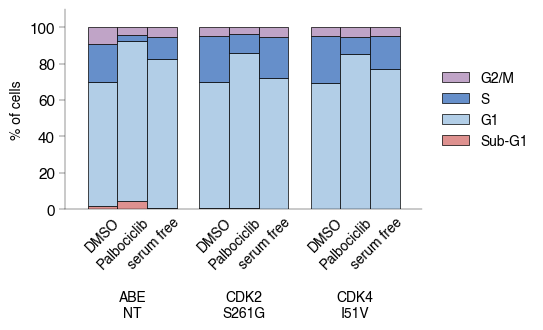

In [7]:
fig1a = plot_stacked_group(grouped, ABE_LINES, "ABE-derived")
fig1a.savefig(f"{OUT_PREFIX}_ABE.svg", bbox_inches="tight")
fig1a.savefig(f"{OUT_PREFIX}_ABE.png", dpi=200, bbox_inches="tight")
print(f"Saved {OUT_PREFIX}_ABE.svg and {OUT_PREFIX}_ABE.png")
plt.show()

## Figure 1b — stacked bar, CBE-derived lines

Saved T47D_cell_cycle_stacked_CBE.svg and T47D_cell_cycle_stacked_CBE.png


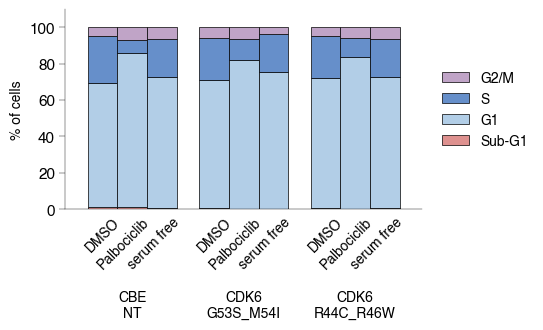

In [8]:
fig1b = plot_stacked_group(grouped, CBE_LINES, "CBE-derived")
fig1b.savefig(f"{OUT_PREFIX}_CBE.svg", bbox_inches="tight")
fig1b.savefig(f"{OUT_PREFIX}_CBE.png", dpi=200, bbox_inches="tight")
print(f"Saved {OUT_PREFIX}_CBE.svg and {OUT_PREFIX}_CBE.png")
plt.show()

## Figure 1c/1d — helper: stacked bar, DMSO + Palbo only, grouped by treatment

Same Sub-G1 / G1 / S / G2-M stacked composition as Figure 1, but restricted to
`STACKED_BYTREATMENT_ORDER` (DMSO and Palbo; serum free excluded) and laid out like the
%S-phase plots (Figure 2): one group per treatment, with the cell lines as the bars within
each group in `ABE_LINES` / `CBE_LINES` order. Each bar is labeled with its cell line
(angled, under the bar), and the treatment name sits below as the group label.
`NORMALIZE_TO_100` applies here too. Size and label spacing are set by the
`STACKED_BYTREATMENT_*` settings in the Configuration cell.


In [9]:
def plot_stacked_by_treatment(grouped, cell_lines_g, label, treatments=STACKED_BYTREATMENT_ORDER,
                              normalize=NORMALIZE_TO_100):
    """Stacked phase bars grouped by treatment; cell lines are the bars within each group."""
    n_groups_g = len(treatments)
    n_bars_g = len(cell_lines_g)
    bar_w_g = GROUP_WIDTH / n_bars_g
    x_pos = {}
    for gi, tr in enumerate(treatments):
        for ti, cl in enumerate(cell_lines_g):
            x_pos[(tr, cl)] = gi + (ti - (n_bars_g - 1) / 2) * bar_w_g

    fig, ax = plt.subplots(figsize=STACKED_BYTREATMENT_FIGSIZE)
    bar_labels = []
    for (tr, cl), x in x_pos.items():
        row = grouped[(grouped.CellLine == cl) & (grouped.Treatment == tr)]
        if row.empty:
            continue
        vals = row.iloc[0][PHASE_ORDER].astype(float)
        if normalize:
            vals = vals / vals.sum() * 100
        bottom = 0.0
        for phase in PHASE_ORDER:
            val = float(vals[phase])
            ax.bar(x, val, bottom=bottom, width=bar_w_g,  # full slot width -> bars within a treatment touch
                   color=PHASE_COLORS[phase], edgecolor="black", linewidth=0.3)
            bottom += val
        # Per-bar cell-line label; offset in points so the gap is the same at any figure height.
        bar_labels.append(ax.annotate(format_cellline_label(cl), xy=(x + bar_w_g / 3, 0), xycoords="data",
                    xytext=(0, -4), textcoords="offset points", ha="right", va="top",
                    rotation=STACKED_BYTREATMENT_LABEL_ROTATION, rotation_mode="anchor", fontsize=10))

    ax.set_xticks(range(n_groups_g))
    ax.set_xticklabels([TREATMENT_LABELS.get(tr, tr) for tr in treatments], fontsize=10)
    pad = STACKED_BYTREATMENT_LABEL_PAD
    if pad is None and bar_labels:
        # Measure the rendered cell-line labels and put the treatment labels just below the lowest one.
        fig.canvas.draw()
        renderer = fig.canvas.get_renderer()
        lowest_px = min(a.get_window_extent(renderer).y0 for a in bar_labels)
        axis_px = ax.get_window_extent(renderer).y0
        pad = (axis_px - lowest_px) * 72 / fig.dpi + 4
    ax.tick_params(axis="x", pad=pad if pad is not None else 8, length=0)
    ax.tick_params(axis="y", length=4, width=0.3)
    ax.set_xlim(-0.6, n_groups_g - 1 + 0.6)
    ax.set_ylabel("% of cells", fontsize=10)
    ax.set_ylim(0, 110)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    ax.spines["left"].set_linewidth(0.3)
    ax.spines["bottom"].set_linewidth(0.3)

    # Same right-side phase legend as Figure 1 (top-to-bottom matches the stacking order).
    legend_order = list(reversed(PHASE_ORDER))
    legend_handles = [plt.Rectangle((0, 0), 1, 1, facecolor=PHASE_COLORS[p], edgecolor="black", linewidth=0.3)
                      for p in legend_order]
    ax.legend(legend_handles, [PHASE_LABELS[p] for p in legend_order], loc="center left",
              bbox_to_anchor=(1.02, 0.5), frameon=False, fontsize=10)
    return fig

## Figure 1c — stacked bar, DMSO + Palbo, ABE-derived lines


Saved T47D_cell_cycle_stacked_DMSO_Palbo_ABE.svg and T47D_cell_cycle_stacked_DMSO_Palbo_ABE.png


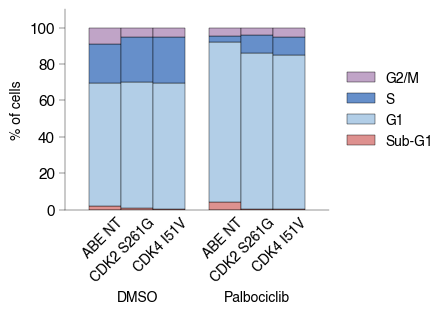

In [10]:
fig1c = plot_stacked_by_treatment(grouped, ABE_LINES, "ABE-derived")
fig1c.savefig(f"{OUT_PREFIX}_DMSO_Palbo_ABE.svg", bbox_inches="tight")
fig1c.savefig(f"{OUT_PREFIX}_DMSO_Palbo_ABE.png", dpi=200, bbox_inches="tight")
print(f"Saved {OUT_PREFIX}_DMSO_Palbo_ABE.svg and {OUT_PREFIX}_DMSO_Palbo_ABE.png")
plt.show()

## Figure 1d — stacked bar, DMSO + Palbo, CBE-derived lines


Saved T47D_cell_cycle_stacked_DMSO_Palbo_CBE.svg and T47D_cell_cycle_stacked_DMSO_Palbo_CBE.png


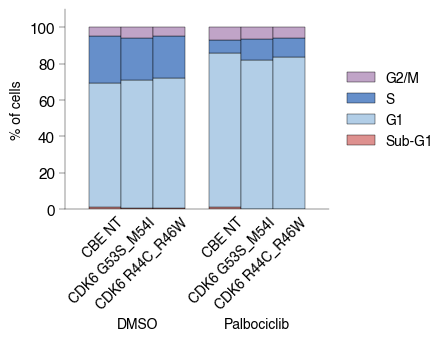

In [11]:
fig1d = plot_stacked_by_treatment(grouped, CBE_LINES, "CBE-derived")
fig1d.savefig(f"{OUT_PREFIX}_DMSO_Palbo_CBE.svg", bbox_inches="tight")
fig1d.savefig(f"{OUT_PREFIX}_DMSO_Palbo_CBE.png", dpi=200, bbox_inches="tight")
print(f"Saved {OUT_PREFIX}_DMSO_Palbo_CBE.svg and {OUT_PREFIX}_DMSO_Palbo_CBE.png")
plt.show()

## Statistical testing — %S phase vs the NT control

Compares each variant's **Palbo** %S-phase replicates against its base-editor system's
**NT control's Palbo** replicates (not against its own DMSO) using Welch's two-sided t-test
(unequal variances):
`CDK2_S261G`/`CDK4_I51V` vs `ABE_NT`, and `CDK6_G53S`/`CDK6_R46W` vs `CBE_NT`.
This tests whether a variant fails to arrest in Palbo as completely as the matched NT
control (i.e. Palbo resistance), rather than whether Palbo changes %S relative to that
cell line's own DMSO.

The same test is also run within **DMSO** (variant DMSO vs NT DMSO) to show any baseline
difference in %S; both sets of brackets are drawn on Figure 2 (`SPHASE_SIG_TREATMENTS`).

p-values are **Bonferroni-corrected**: `p_adj = min(p × m, 1)`, where `m` is the number of
tests in the family set by `BONFERRONI_FAMILY` (`"figure"` = all variant-vs-NT comparisons
on one plot, across DMSO and Palbo; `"treatment"` = only those within the same treatment).
The tables keep both the raw `p_value` and `p_adj`, plus `m`.

Asterisks (from `p_adj`): `*` p<0.05, `**` p<0.01, `***` p<0.001, else `ns`.

In [12]:
def p_to_asterisks(p):
    if p < 0.001:
        return "***"
    if p < 0.01:
        return "**"
    if p < 0.05:
        return "*"
    return "ns"


def compute_significance_vs_control(merged, cell_lines, control, treatment, value_col="S"):
    """Welch's two-sided t-test: each cell line's `treatment` replicates vs `control`'s
    `treatment` replicates. Returns raw p-values; see apply_bonferroni for the correction."""
    rows = []
    control_vals = merged[(merged.CellLine == control) & (merged.Treatment == treatment)][value_col].values
    for cl in cell_lines:
        if cl == control:
            continue
        treat_vals = merged[(merged.CellLine == cl) & (merged.Treatment == treatment)][value_col].values
        if len(control_vals) < 2 or len(treat_vals) < 2:
            p = float("nan")
        else:
            _, p = stats.ttest_ind(treat_vals, control_vals, equal_var=False, alternative="two-sided")
        rows.append({
            "CellLine": cl, "Treatment": treatment, "vs_control": control,
            "n_control": len(control_vals), "n_treatment": len(treat_vals),
            "p_value": p,
        })
    return pd.DataFrame(rows)


def apply_bonferroni(sig, family=BONFERRONI_FAMILY):
    """Add Bonferroni-adjusted p-values (p_adj = min(p * m, 1)) and asterisks from p_adj.
    family="figure": m = all tests in `sig`; family="treatment": m = tests within each treatment.
    Tests with NaN p-values (n < 2) don't count toward m."""
    sig = sig.copy()
    if family == "figure":
        m = pd.Series(sig["p_value"].notna().sum(), index=sig.index)
    elif family == "treatment":
        m = sig.groupby("Treatment")["p_value"].transform(lambda s: s.notna().sum())
    else:
        raise ValueError(f"BONFERRONI_FAMILY must be 'figure' or 'treatment', got {family!r}")
    sig["m"] = m.astype(int)
    sig["p_adj"] = (sig["p_value"] * sig["m"]).clip(upper=1.0)
    sig["sig"] = sig["p_adj"].apply(lambda p: p_to_asterisks(p) if p == p else "n/a")
    return sig


sig_abe = apply_bonferroni(pd.concat([compute_significance_vs_control(merged, ABE_LINES, "ABE_NT", tr)
                                      for tr in SPHASE_SIG_TREATMENTS], ignore_index=True))
sig_abe

,CellLine,Treatment,vs_control,n_control,n_treatment,p_value,m,p_adj,sig
0,CDK2_S261G,DMSO,ABE_NT,3,3,0.015095,4,0.060380,ns
1,CDK4_I51V,DMSO,ABE_NT,3,3,0.002288,4,0.009151,**
2,CDK2_S261G,Palbo,ABE_NT,3,3,0.000679,4,0.002718,**
3,CDK4_I51V,Palbo,ABE_NT,3,3,0.000308,4,0.001232,**


In [13]:
sig_cbe = apply_bonferroni(pd.concat([compute_significance_vs_control(merged, CBE_LINES, "CBE_NT", tr)
                                      for tr in SPHASE_SIG_TREATMENTS], ignore_index=True))
sig_cbe

,CellLine,Treatment,vs_control,n_control,n_treatment,p_value,m,p_adj,sig
0,CDK6_G53S,DMSO,CBE_NT,3,3,0.076227,4,0.304908,ns
1,CDK6_R46W,DMSO,CBE_NT,3,3,0.067153,4,0.268613,ns
2,CDK6_G53S,Palbo,CBE_NT,3,3,0.003824,4,0.015295,*
3,CDK6_R46W,Palbo,CBE_NT,3,3,0.001945,4,0.007778,**


## Figure 2 — helper

Dot + bar + SD chart for one base-editor group's cell lines, with significance brackets
from the NT control's bar to each variant's bar within each treatment in `SPHASE_SIG_TREATMENTS`
(DMSO and Palbo); asterisks use the Bonferroni-adjusted p-values. Bracket height clears every
bar/dot in between (not just the two compared bars), and comparisons spanning more cell
lines are stacked higher so their bracket arcs over the narrower ones.

In [14]:
def span_max_value(merged, x_pos, x1, x2):
    """Max %S value (bar/dot) among all bars whose x-position falls within [x1, x2]."""
    lo, hi = sorted([x1, x2])
    vals = []
    for (tr, cl), x in x_pos.items():
        if lo - 1e-9 <= x <= hi + 1e-9:
            sub = merged[(merged.CellLine == cl) & (merged.Treatment == tr)]["S"]
            if not sub.empty:
                vals.append(sub.max())
    return max(vals) if vals else 0.0


def plot_s_phase_group(merged, cell_lines_g, control, label, treatments=SPHASE_TREATMENT_ORDER):
    """Bars grouped by treatment (SPHASE_TREATMENT_ORDER); cell lines are the bars
    within each group, colored by CELL_LINE_COLORS."""
    n_groups_g = len(treatments)
    n_bars_g = len(cell_lines_g)
    bar_w_g = GROUP_WIDTH / n_bars_g
    x_pos = {}
    for gi, tr in enumerate(treatments):
        for ti, cl in enumerate(cell_lines_g):
            x_pos[(tr, cl)] = gi + (ti - (n_bars_g - 1) / 2) * bar_w_g

    s_grouped = merged.groupby(["CellLine", "Treatment"])["S"].agg(["mean", "std"]).reset_index()

    fig, ax = plt.subplots(figsize=(max(2.8, 1.1 * n_groups_g * (n_bars_g / 3)), SPHASE_FIG_HEIGHT))

    for (tr, cl), x in x_pos.items():
        row = s_grouped[(s_grouped.CellLine == cl) & (s_grouped.Treatment == tr)]
        if row.empty:
            continue
        mean = float(row["mean"].iloc[0])
        sd = float(row["std"].iloc[0])
        ax.bar(x, mean, width=bar_w_g, facecolor="white", edgecolor="black", linewidth=0.3, zorder=2)
        ax.errorbar(x, mean, yerr=sd, ecolor="black", elinewidth=0.4, capsize=3, capthick=0.6, fmt="none", zorder=2)
        vals = merged[(merged.CellLine == cl) & (merged.Treatment == tr)]["S"].values
        for j, v in enumerate(vals):
            offset = (j - (len(vals) - 1) / 2) * bar_w_g * 0.28
            ax.scatter(x + offset, v, s=30, color=CELL_LINE_COLORS.get(cl, "#888888"),
                       edgecolor="black", linewidth=0.35, zorder=3)

    sig_treatments = [tr for tr in SPHASE_SIG_TREATMENTS if tr in treatments]
    sig = apply_bonferroni(pd.concat([compute_significance_vs_control(merged, cell_lines_g, control, tr)
                                      for tr in sig_treatments], ignore_index=True))

    bracket_step = 3
    base_gap = 3
    h = 1
    tops = []
    for tr in sig_treatments:
        comparisons = []
        for cl in cell_lines_g:
            if cl == control:
                continue
            x1 = x_pos[(tr, control)]
            x2 = x_pos[(tr, cl)]
            comparisons.append((cl, x1, x2, abs(x2 - x1)))
        comparisons.sort(key=lambda c: c[3])  # narrowest span first -> lowest bracket

        y_prev = None  # brackets stack independently within each treatment group
        for cl, x1, x2, span in comparisons:
            floor = span_max_value(merged, x_pos, x1, x2) + base_gap
            y = floor if y_prev is None else max(floor, y_prev + bracket_step)
            y_prev = y
            row = sig[(sig.CellLine == cl) & (sig.Treatment == tr)].iloc[0]
            lo, hi = sorted([x1, x2])
            ax.plot([lo, lo, hi, hi], [y, y + h, y + h, y], color="black", linewidth=0.3)
            ax.text((lo + hi) / 2, y + h, row["sig"], ha="center", va="bottom", fontsize=7)
            tops.append(y + h)

    ax.set_xticks(range(n_groups_g))
    ax.set_xticklabels([TREATMENT_LABELS.get(tr, tr) for tr in treatments], fontsize=8)
    ax.tick_params(axis="x", pad=8, length=0)
    ax.tick_params(axis="y", labelsize=7, width=0.3)
    for spine in ax.spines.values():
        spine.set_linewidth(0.8)
    ax.set_xlim(-0.6, n_groups_g - 1 + 0.6)
    ax.set_ylabel("% S phase cells", fontsize=9)
    # y-limit must clear both the tallest significance bracket AND the tallest plotted
    # data point -- with treatment-grouped bars, the tallest dot isn't necessarily under
    # a bracket. Only treatments actually plotted count, so excluded conditions (e.g.
    # serum free) don't inflate the axis.
    data_max = float(merged[merged.CellLine.isin(cell_lines_g) & merged.Treatment.isin(treatments)]["S"].max())
    top = max((max(tops) + 6) if tops else 0.0, data_max + 4) * 1.1
    ax.set_ylim(0, top)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    ax.spines["left"].set_linewidth(0.3)
    ax.spines["bottom"].set_linewidth(0.3)

    # Variant identity via a vertical color-key legend in the top-right corner,
    # instead of per-bar x-axis labels.
    legend_handles = [
        plt.Line2D([0], [0], marker="o", linestyle="", markerfacecolor=CELL_LINE_COLORS.get(cl, "#888888"),
                   markeredgecolor="black", markersize=5, markeredgewidth=0.35)
        for cl in cell_lines_g
    ]
    ax.legend(legend_handles, [format_cellline_label(cl) for cl in cell_lines_g], loc="upper right",
              frameon=False, fontsize=7)
    return fig, sig


## Figure 2a — %S phase, ABE-derived lines

Saved T47D_cell_cycle_stacked_Sphase_ABE.svg and T47D_cell_cycle_stacked_Sphase_ABE.png


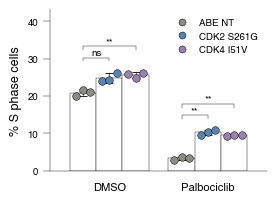

In [15]:
fig2a, sig_abe = plot_s_phase_group(merged, ABE_LINES, "ABE_NT", "ABE-derived")
fig2a.savefig(f"{OUT_PREFIX}_Sphase_ABE.svg", bbox_inches="tight")
fig2a.savefig(f"{OUT_PREFIX}_Sphase_ABE.png", dpi=200, bbox_inches="tight")
print(f"Saved {OUT_PREFIX}_Sphase_ABE.svg and {OUT_PREFIX}_Sphase_ABE.png")
plt.show()

## Figure 2b — %S phase, CBE-derived lines

Saved T47D_cell_cycle_stacked_Sphase_CBE.svg and T47D_cell_cycle_stacked_Sphase_CBE.png


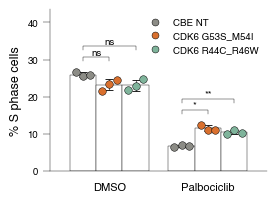

In [16]:
fig2b_sub, sig_cbe_sub = plot_s_phase_group(merged, CBE_LINES, "CBE_NT", "CBE-derived")
fig2b_sub.savefig(f"{OUT_PREFIX}_Sphase_CBE.svg", bbox_inches="tight")
fig2b_sub.savefig(f"{OUT_PREFIX}_Sphase_CBE.png", dpi=200, bbox_inches="tight")
print(f"Saved {OUT_PREFIX}_Sphase_CBE.svg and {OUT_PREFIX}_Sphase_CBE.png")
plt.show()